# BERT Question Answering — Practice Notebook

Use the same concepts and approach as the given notebook.

Do not use solutions or hints. Complete each practice section yourself.


## Practice 1 — Imports

Import the libraries and classes needed for:
- BERT question answering
- BERT tokenizer
- PyTorch


In [55]:
from transformers import DistilBertForQuestionAnswering, DistilBertTokenizer
import torch
import seaborn as sns
import re

## Practice 2 — Model Name

Create a variable named `model_name` containing the BERT model used in the original notebook.


In [2]:
model_name = "distilbert-base-uncased-distilled-squad"

## Practice 3 — Load the Model

Load the question-answering model using `BertForQuestionAnswering.from_pretrained()`.


In [3]:
model = DistilBertForQuestionAnswering.from_pretrained(model_name)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

## Practice 4 — Load the Tokenizer

Load the tokenizer using `BertTokenizer.from_pretrained()`.


In [4]:
tokenizer = DistilBertTokenizer.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## Practice 5 — Question and Document

Create the following variables:

- `question = "Where is the Eiffel Tower located?"`
- `answer_document = "The Eiffel Tower is located in Paris, France. It was completed in 1889 and became one of the most recognizable landmarks in the world."`


In [5]:
question = "Where is the Eiffel Tower located?"
answer_document = "The Eiffel Tower is located in Paris, France. It was completed in 1889 and became one of the most recognizable landmarks in the world."

## Practice 6 — Encode the Question and Document

Use `tokenizer.encode_plus()` to encode the question and answer document together.

Store the result in a variable named `encoding`.


In [6]:
tokenizer_data = tokenizer(question, answer_document)
tokenizer_data

{'input_ids': [101, 2073, 2003, 1996, 1041, 13355, 2884, 3578, 2284, 1029, 102, 1996, 1041, 13355, 2884, 3578, 2003, 2284, 1999, 3000, 1010, 2605, 1012, 2009, 2001, 2949, 1999, 6478, 1998, 2150, 2028, 1997, 1996, 2087, 20123, 16209, 1999, 1996, 2088, 1012, 102], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

## Practice 8 — Extract the Encoded Values

Create these three variables from `encoding`:

- `inputs`
- `sentence_embedding`
- `tokens`

`tokens` should contain the token strings converted from the input IDs.


In [7]:
inputs = tokenizer_data["input_ids"]
attention_mask = tokenizer_data["attention_mask"]
tokens = tokenizer.convert_ids_to_tokens(inputs)
print(tokens)

['[CLS]', 'where', 'is', 'the', 'e', '##iff', '##el', 'tower', 'located', '?', '[SEP]', 'the', 'e', '##iff', '##el', 'tower', 'is', 'located', 'in', 'paris', ',', 'france', '.', 'it', 'was', 'completed', 'in', '1889', 'and', 'became', 'one', 'of', 'the', 'most', 'recognizable', 'landmarks', 'in', 'the', 'world', '.', '[SEP]']


## Practice 9 — Special Tokens

Use the tokenizer to decode the token IDs:

- `101`
- `102`

Print both results.


In [8]:
tokenizer.decode(101)

'[CLS]'

In [9]:
tokenizer.decode(102)

'[SEP]'

## Practice 10 — Model Prediction

Pass the encoded question and document to the model.

Store the model output in a variable named `output`.


In [10]:
output = model(input_ids = torch.tensor([inputs]), attention_mask = torch.tensor([attention_mask]))

## Practice 11 — Start and End Positions

Use `torch.argmax()` on:

- `output.start_logits`
- `output.end_logits`

Store the results in:

- `start_index`
- `end_index`

Print both indices.


In [11]:
start_index = torch.argmax(output.start_logits)
end_index = torch.argmax(output.end_logits)

print(start_index)
print(end_index)

tensor(19)
tensor(21)


## Practice 12 — Extract the Answer

Use `start_index`, `end_index`, and `tokens` to extract the predicted answer.

Store it in a variable named `answer` and print it.


In [12]:
answer = ' '.join(tokens[start_index:end_index+1])
print(answer)

paris , france


## Practice 13 — Start and End Logits

Convert:

- `output.start_logits`
- `output.end_logits`

into flattened NumPy arrays.

Store them in:

- `s_scores`
- `e_scores`


In [13]:
s_scores = output.start_logits.detach().numpy().flatten()
e_scores = output.end_logits.detach().numpy().flatten()

print(s_scores)


[-4.717061  -4.460048  -6.3559103 -6.524213  -6.2111526 -7.371866
 -7.683914  -7.2763944 -6.0865617 -6.8768487 -5.518156   1.8090521
  0.3733615 -3.498943  -3.698125  -2.1756344 -0.4206284  2.0527277
  4.557      9.374314  -0.8026725  3.1069922 -2.9742823 -1.7056705
 -4.3660817 -3.2750387 -3.975935  -2.2205453 -6.060697  -5.3310456
 -5.087387  -6.859791  -6.0139937 -6.0126147 -6.1841164 -5.3593965
 -6.8558598 -5.5548363 -5.5011306 -5.968854  -5.5181437]


In [14]:
print(len(s_scores))
print(len(tokens))

41
41


## Practice 14 — Token Labels

Create an empty list named `token_labels`.

Loop through `tokens` with `enumerate()` and create labels containing each token and its index.

Print `token_labels`.


In [15]:
def arrays_for_plot(scores):
  token_labels = []
  meaningful_scores = []
  for (i, token) in enumerate(tokens):
    if(scores[i] > 0):
      token_labels.append('{:} - {:2}'.format(token, i))
      meaningful_scores.append(scores[i])
  return {"token_labels" : token_labels, "meaningful_scores" : meaningful_scores}


## Practice 15 — Plot the Start Scores

Create a plot showing the start logits for all tokens.

Use the token labels on the x-axis.


<Axes: >

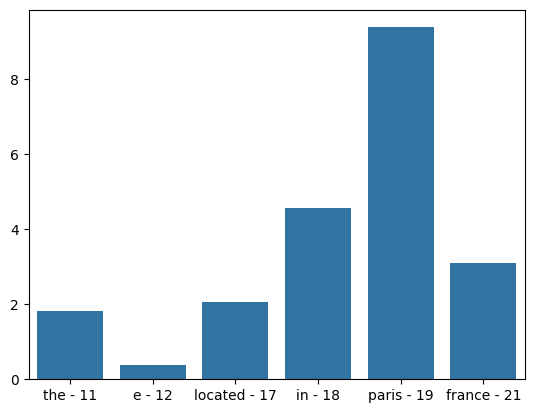

In [16]:
arrays = arrays_for_plot(s_scores)
sns.barplot(x= arrays["token_labels"], y = arrays["meaningful_scores"])

## Practice 16 — Plot the End Scores

Create a plot showing the end logits for all tokens.

Use the token labels on the x-axis.


<Axes: >

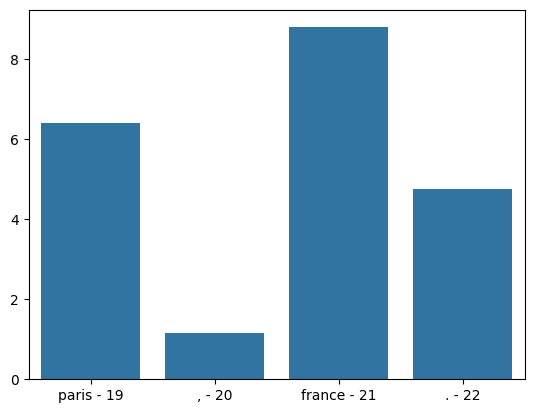

In [17]:
arrays = arrays_for_plot(e_scores)
sns.barplot(x= arrays["token_labels"], y = arrays["meaningful_scores"])

## Practice 17 — Complete Question Answering Task

Create a new question and answer document:

- `question = "What year did the first man land on the Moon?"`
- Use a document containing the answer.

Then perform the complete process:

1. Encode the question and document.
2. Extract the input IDs, token type IDs, and tokens.
3. Run the model.
4. Find the start and end indices.
5. Extract and print the predicted answer.


In [50]:

document = 'Apollo 11 landed on the Moon on July 20, 1969. Neil Armstrong was the first person to step onto the lunar surface, followed shortly by Buzz Aldrin. Armstrong described the moment as “one small step for man, one giant leap for mankind.” The astronauts collected samples and conducted experiments before returning safely to Earth. The first man landed on the Moon in 1969.'

## Practice 18 — Complete Question Answering Task

Create another question and answer document of your choice.

Repeat the complete BERT question-answering process from encoding through answer extraction.


In [ ]:
def faqbot(query):
    encode = tokenizer(query, document)
    tokens = tokenizer.convert_ids_to_tokens(encode['input_ids'])
    #print(encode)
    sep_index = encode['input_ids'].index(tokenizer.sep_token_id)
    q = sep_index + 1
    a = len(encode['input_ids']) - q
    segment_ids = [0]*q + [1]*a
    output = model(input_ids = torch.tensor([encode['input_ids']]) , token_type_ids = torch.tensor([segment_ids]))
    start_index = torch.argmax(output.start_logits)
    end_index = torch.argmax(output.end_logits)
    
    if(start_index > end_index):
        answer = 'sorry I can\'t answer that'
    else:
        answer = ' '.join(tokens[start_index:end_index+1])
        answer = re.sub(' ##', '', answer)

    return answer


    

In [65]:
faqbot('what is the age of Neil Armstrong ?')

'what is the age of neil armstrong ? [SEP] apollo 11 landed on the moon on july 20 , 1969'